# Adult source distributions

These plots use the unchanged official records. They describe the data; they do not estimate leakage accuracy. Only aggregate outputs are retained.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, io, contextlib
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'src/leakage_audit/audit.py').exists()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))
RUN = ROOT / 'data/interim' / ('analysis-' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
RUN.mkdir(parents=True, exist_ok=False)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print('Fresh analysis directory:', RUN.relative_to(ROOT))

Fresh analysis directory: data\interim\analysis-20261016T075510539331Z


In [2]:
from leakage_audit.adult_validation import validate
from leakage_audit import read_csv
from leakage_audit.audit import missing, audit, AuditConfig
with contextlib.redirect_stdout(io.StringIO()): validate(report=RUN / 'adult-source.json')
train = read_csv('data/processed/adult/train.csv')
test = read_csv('data/processed/adult/test.csv')
print({'train':len(train), 'heldout':len(test), 'columns':len(train[0])})

{'train': 32561, 'heldout': 16281, 'columns': 15}


## Missing fields
The source uses question marks for unknown values; preparation converts them to empty CSV fields. Compare the fractions rather than counts because split sizes differ.

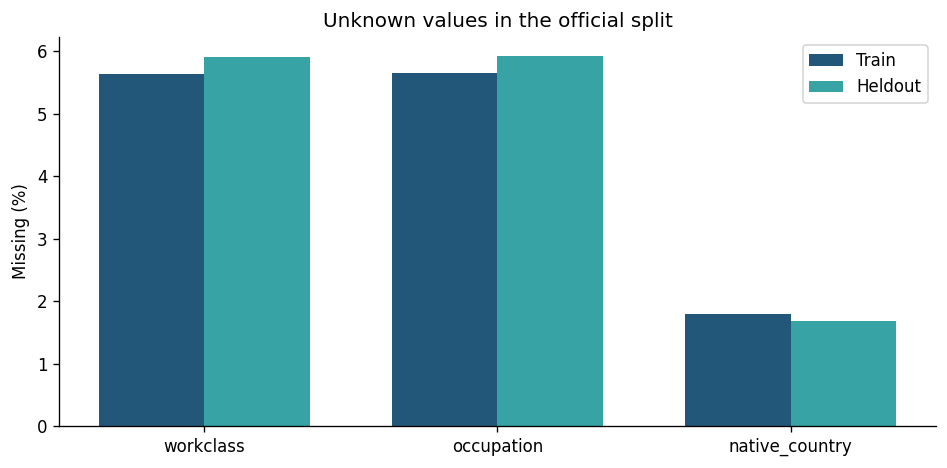

In [3]:
columns=[c for c in train[0] if c!='target']
train_missing=np.array([sum(missing(r[c]) for r in train)/len(train) for c in columns])
test_missing=np.array([sum(missing(r[c]) for r in test)/len(test) for c in columns])
keep=(train_missing+test_missing)>0
names=np.array(columns)[keep];x=np.arange(len(names))
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(x-.18,train_missing[keep]*100,.36,label='Train',color='#22577a')
ax.bar(x+.18,test_missing[keep]*100,.36,label='Heldout',color='#38a3a5')
ax.set(xticks=x,xticklabels=names,ylabel='Missing (%)',title='Unknown values in the official split')
ax.legend();fig.tight_layout();fig.savefig(RUN/'missingness.png');plt.show()

## Age and hours worked
Histogram bins are fixed here before plotting. Source values remain unchanged. Similar shapes do not prove that an evaluation split is valid.

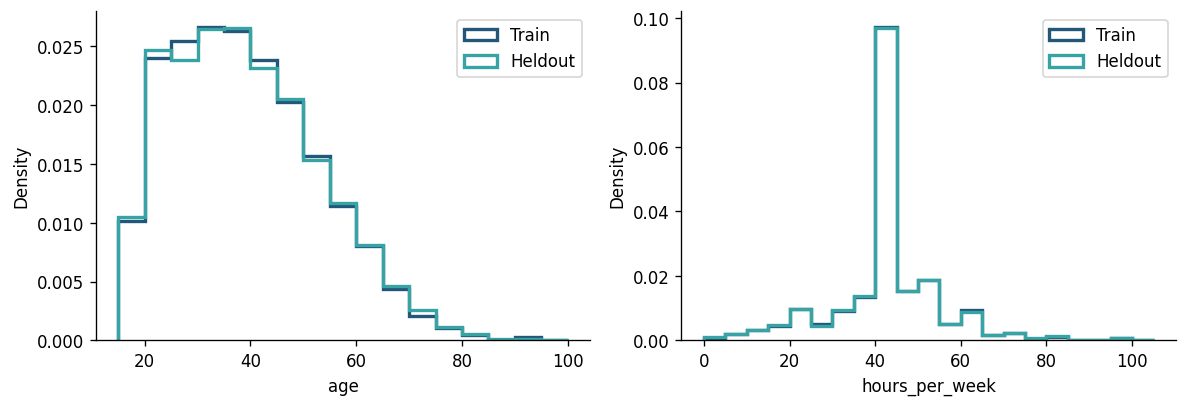

In [4]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for ax,column,bins in zip(axes,['age','hours_per_week'],[np.arange(15,101,5),np.arange(0,106,5)]):
    for rows,label,color in [(train,'Train','#22577a'),(test,'Heldout','#38a3a5')]:
        values=[float(r[column]) for r in rows if not missing(r[column])]
        ax.hist(values,bins=bins,density=True,histtype='step',linewidth=2,label=label,color=color)
    ax.set(xlabel=column,ylabel='Density');ax.legend()
fig.tight_layout();fig.savefig(RUN/'numeric-distributions.png');plt.show()

## Workclass composition
Compare category proportions including missingness. Rare categories remain visible rather than being removed to improve a metric.

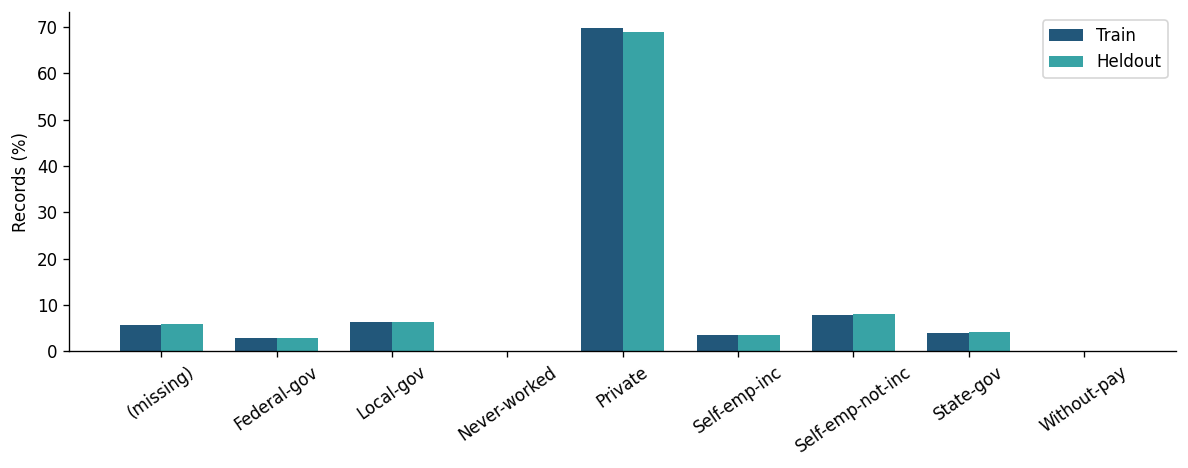

In [5]:
from collections import Counter
categories=sorted({r['workclass'] or '(missing)' for r in train+test})
fractions=[]
for rows in (train,test):
    counts=Counter(r['workclass'] or '(missing)' for r in rows)
    fractions.append([counts[c]/len(rows)*100 for c in categories])
x=np.arange(len(categories));fig,ax=plt.subplots(figsize=(10,4))
ax.bar(x-.18,fractions[0],.36,label='Train',color='#22577a')
ax.bar(x+.18,fractions[1],.36,label='Heldout',color='#38a3a5')
ax.set(xticks=x,xticklabels=categories,ylabel='Records (%)');ax.tick_params(axis='x',rotation=35);ax.legend()
fig.tight_layout();fig.savefig(RUN/'workclass.png');plt.show()

## What to investigate next
Missingness and composition appear close across the official splits, but those checks do not detect every dependency. Repeated feature vectors, survey design, collection timing and deployment conditions require separate evidence. This dataset has no reliable entity or observation-time field for a natural longitudinal leakage test.